### Setup
We import `geopandas` as well to help us create the map diagrams below.

In [9]:
%pip install -r packages.txt # get the packages from packages.txt file

import warnings
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import plotnine as p9
from scipy import stats
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 4002
np.random.seed(SEED)


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Clean the census

In [10]:
raw = pd.read_csv("../data/raw/census_2026_subzone_age_sex.csv")
raw

,"Resident Population by Planning Area/Subzone, Single Year of Age and Sex, June 2026",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,Planning Area,Subzone,Age,Sex,2026
2,Total,Total,Total,Total,"4,231,520"
3,Total,Total,Total,Males,"2,055,410"
4,Total,Total,Total,Females,"2,176,120"
...,...,...,...,...,...
107091,Note:,NaN,NaN,NaN,NaN
107092,Planning areas refer to areas demarcated in th...,NaN,NaN,NaN,NaN
107093,Data from 2003 onwards excludes residents who ...,NaN,NaN,NaN,NaN
107094,"""-"" denotes Nil or negligible.",NaN,NaN,NaN,NaN


In [ ]:
raw.columns = ["planning_area", "subzone", "age", "sex", "pop"] # rename the columns
raw = raw.dropna() # drop all the NA values
raw

,planning_area,subzone,age,sex,pop
1,Planning Area,Subzone,Age,Sex,2026
2,Total,Total,Total,Total,"4,231,520"
3,Total,Total,Total,Males,"2,055,410"
4,Total,Total,Total,Females,"2,176,120"
5,Total,Total,0,Total,"26,060"
...,...,...,...,...,...
107085,Yishun,Yishun West,89,Males,20
107086,Yishun,Yishun West,89,Females,50
107087,Yishun,Yishun West,90 & Over,Total,330
107088,Yishun,Yishun West,90 & Over,Males,110


In [12]:
raw_sample = raw.sample(n=500, random_state=47) # get a better idea of what we are dealing with
raw_sample

,planning_area,subzone,age,sex,pop
100379,Western Islands,Sudong,62,Total,-
53811,Novena,Total,87,Males,70
84038,Simpang,Simpang North,43,Total,-
16262,Bukit Merah,Tiong Bahru,83,Total,70
96280,Toa Payoh,Potong Pasir,75,Females,100
...,...,...,...,...,...
63077,Pioneer,Joo Koon,48,Total,-
6727,Bishan,Bishan East,32,Females,220
8779,Boon Lay,Tukang,72,Females,-
62616,Pioneer,Gul Basin,78,Males,-


In [13]:
ages = raw[ # create a new file called age from raw
    (raw.planning_area != "Total") # don't look at rows where planning area says 'total'
    & (raw.subzone != "Total") # don't look at rows where subzone says 'total'
    & (raw.age != "Total") # don't look at rows where age says 'total'
    & (raw.sex == "Total")
].copy()

ages["pop"] = pd.to_numeric(ages["pop"].str.replace(",", "").replace("-", "0")) # remove the comma and replace the '-' with 0
ages["age"] = ages["age"].str.replace(" & Over", "").astype(int)  # replace "90 & Over" with 90
ages

,planning_area,subzone,age,sex,pop
557,Ang Mo Kio,Ang Mo Kio Town Centre,0,Total,10
560,Ang Mo Kio,Ang Mo Kio Town Centre,1,Total,20
563,Ang Mo Kio,Ang Mo Kio Town Centre,2,Total,20
566,Ang Mo Kio,Ang Mo Kio Town Centre,3,Total,20
569,Ang Mo Kio,Ang Mo Kio Town Centre,4,Total,20
...,...,...,...,...,...
107075,Yishun,Yishun West,86,Total,160
107078,Yishun,Yishun West,87,Total,180
107081,Yishun,Yishun West,88,Total,70
107084,Yishun,Yishun West,89,Total,70


We only want to look at those aged above 65 for our analysis, as that is how old you need to be to be considered an elder in Singapore (see our paper for further explanation).

In [17]:
census = (
    ages.assign(
        pop65=lambda d: d["pop"].where(d.age >= 65), # look at the population variable and keep all those whose age are above 65. otherwise, put their age as 0
    )
    .groupby(["planning_area", "subzone"], as_index=False)[["pop", "pop65"]]
    .sum() # sum up all the people whose ages are above 65 for each subzone
)
census

,planning_area,subzone,pop,pop65
0,Ang Mo Kio,Ang Mo Kio Town Centre,4830,990.0
1,Ang Mo Kio,Cheng San,26150,7130.0
2,Ang Mo Kio,Chong Boon,24420,7550.0
3,Ang Mo Kio,Kebun Bahru,21440,5960.0
4,Ang Mo Kio,Sembawang Hills,6940,1570.0
...,...,...,...,...
327,Yishun,Springleaf,4380,1050.0
328,Yishun,Yishun Central,2860,480.0
329,Yishun,Yishun East,77880,10370.0
330,Yishun,Yishun South,40540,8440.0


Let us now calculate the % of elderly people in each subzone, and call it `pct65`.

In [18]:
census["pct65"] = 100 * census.pop65 / census["pop"]
census

,planning_area,subzone,pop,pop65,pct65
0,Ang Mo Kio,Ang Mo Kio Town Centre,4830,990.0,20.496894
1,Ang Mo Kio,Cheng San,26150,7130.0,27.265774
2,Ang Mo Kio,Chong Boon,24420,7550.0,30.917281
3,Ang Mo Kio,Kebun Bahru,21440,5960.0,27.798507
4,Ang Mo Kio,Sembawang Hills,6940,1570.0,22.622478
...,...,...,...,...,...
327,Yishun,Springleaf,4380,1050.0,23.972603
328,Yishun,Yishun Central,2860,480.0,16.783217
329,Yishun,Yishun East,77880,10370.0,13.315357
330,Yishun,Yishun South,40540,8440.0,20.818944


Since there are too many subzones to take in with one glance, let's find out which subzones have the highest number of elderly.

In [19]:
print(f"{len(census)} subzones in {census.planning_area.nunique()} planning areas") # print out number of subzones and planning areas
census.sort_values("pop65", ascending=False).head(10) # list out the subzones with highest number of elderly

332 subzones in 55 planning areas


,planning_area,subzone,pop,pop65,pct65
276,Tampines,Tampines East,124840,28540.0,22.861262
13,Bedok,Bedok North,79570,21100.0,26.517532
278,Tampines,Tampines West,93210,17140.0,18.388585
319,Woodlands,Woodlands East,97800,12740.0,13.026585
15,Bedok,Bedok South,47810,12510.0,26.166074
129,Jurong West,Hong Kah,50620,12150.0,24.002371
135,Jurong West,Yunnan,64710,11960.0,18.482460
331,Yishun,Yishun West,50190,11750.0,23.411038
109,Hougang,Hougang West,42120,11120.0,26.400760
250,Sengkang,Rivervale,62090,10750.0,17.313577


## 2. Creating the geographical data

Since just looking at the data in a table is rough on the eyes, let's plot it on a map. To begin, we create the `subzones` variable from the `mp2019_subzone_no_sea.geosjon` file.

In [20]:
SVY21 = 3414 # the coordinate system for singapore
subzones = gpd.read_file("../data/raw/mp2019_subzone_no_sea.geojson").to_crs(SVY21) # change data into SVY21
subzones

,OBJECTID,SUBZONE_NO,SUBZONE_N,SUBZONE_C,CA_IND,PLN_AREA_N,PLN_AREA_C,REGION_N,REGION_C,INC_CRC,FMEL_UPD_D,SHAPE.AREA,SHAPE.LEN,geometry
0,676,12,DEPOT ROAD,BMSZ12,N,BUKIT MERAH,BM,CENTRAL REGION,CR,C22DED671DE2A940,20191223152313,4.422975e+05,4281.667289,"POLYGON ((25910.344 29425.34, 25880.344 29441...."
1,677,2,BUKIT MERAH,BMSZ02,N,BUKIT MERAH,BM,CENTRAL REGION,CR,085EF219A5A1AEAD,20191223152313,4.117228e+05,3074.963234,"POLYGON ((26750.092 29216.098, 26750.091 29224..."
2,678,3,CHINATOWN,OTSZ03,Y,OUTRAM,OT,CENTRAL REGION,CR,EF2B9A91AF49E025,20191223152313,5.872227e+05,4297.599898,"POLYGON ((29161.201 29723.071, 29147.201 29734..."
3,679,4,PHILLIP,DTSZ04,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,615D4EDDEF809F8E,20191223152313,3.943794e+04,871.554888,"POLYGON ((29814.107 29616.894, 29814.868 29619..."
4,680,5,RAFFLES PLACE,DTSZ05,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,72107B11807074F4,20191223152313,1.887675e+05,1872.752161,"POLYGON ((30137.768 29843.194, 30118.735 29880..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,968,1,UPPER THOMSON,BSSZ01,N,BISHAN,BS,CENTRAL REGION,CR,716DA27F6666AB0C,20191223152313,3.849507e+06,10031.378828,"POLYGON ((29036.498 38365.086, 29073.651 38481..."
328,969,5,SHANGRI-LA,AMSZ05,N,ANG MO KIO,AM,NORTH-EAST REGION,NER,9FA8567B39D8D9D7,20191223152313,6.879137e+05,4019.215248,"POLYGON ((28228.195 39216.137, 28182.428 39220..."
329,970,4,TOWNSVILLE,AMSZ04,N,ANG MO KIO,AM,NORTH-EAST REGION,NER,F5558D84EBC2AAA7,20191223152313,5.463938e+05,3313.322844,"POLYGON ((29649.875 38978.996, 29628.516 38980..."
330,971,2,MARYMOUNT,BSSZ02,N,BISHAN,BS,CENTRAL REGION,CR,154AA8659ADDE6D7,20191223152313,1.964145e+06,6383.484708,"POLYGON ((29469.703 36372.102, 29532.234 36656..."


There are 332 rows, which match the 332 subzones we found in the census dataset. Sanity check completed! Now, we link the census and subzone datasets together by creating a `key`.

In [21]:
# join the planning area and subzone names together in this format: 'planning area|subzone'
# str.strip removes any spaces
subzones["key"] = subzones.PLN_AREA_N.str.strip() + "|" + subzones.SUBZONE_N.str.strip()
subzones

,OBJECTID,SUBZONE_NO,SUBZONE_N,SUBZONE_C,CA_IND,PLN_AREA_N,PLN_AREA_C,REGION_N,REGION_C,INC_CRC,FMEL_UPD_D,SHAPE.AREA,SHAPE.LEN,geometry,key
0,676,12,DEPOT ROAD,BMSZ12,N,BUKIT MERAH,BM,CENTRAL REGION,CR,C22DED671DE2A940,20191223152313,4.422975e+05,4281.667289,"POLYGON ((25910.344 29425.34, 25880.344 29441....",BUKIT MERAH|DEPOT ROAD
1,677,2,BUKIT MERAH,BMSZ02,N,BUKIT MERAH,BM,CENTRAL REGION,CR,085EF219A5A1AEAD,20191223152313,4.117228e+05,3074.963234,"POLYGON ((26750.092 29216.098, 26750.091 29224...",BUKIT MERAH|BUKIT MERAH
2,678,3,CHINATOWN,OTSZ03,Y,OUTRAM,OT,CENTRAL REGION,CR,EF2B9A91AF49E025,20191223152313,5.872227e+05,4297.599898,"POLYGON ((29161.201 29723.071, 29147.201 29734...",OUTRAM|CHINATOWN
3,679,4,PHILLIP,DTSZ04,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,615D4EDDEF809F8E,20191223152313,3.943794e+04,871.554888,"POLYGON ((29814.107 29616.894, 29814.868 29619...",DOWNTOWN CORE|PHILLIP
4,680,5,RAFFLES PLACE,DTSZ05,Y,DOWNTOWN CORE,DT,CENTRAL REGION,CR,72107B11807074F4,20191223152313,1.887675e+05,1872.752161,"POLYGON ((30137.768 29843.194, 30118.735 29880...",DOWNTOWN CORE|RAFFLES PLACE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
327,968,1,UPPER THOMSON,BSSZ01,N,BISHAN,BS,CENTRAL REGION,CR,716DA27F6666AB0C,20191223152313,3.849507e+06,10031.378828,"POLYGON ((29036.498 38365.086, 29073.651 38481...",BISHAN|UPPER THOMSON
328,969,5,SHANGRI-LA,AMSZ05,N,ANG MO KIO,AM,NORTH-EAST REGION,NER,9FA8567B39D8D9D7,20191223152313,6.879137e+05,4019.215248,"POLYGON ((28228.195 39216.137, 28182.428 39220...",ANG MO KIO|SHANGRI-LA
329,970,4,TOWNSVILLE,AMSZ04,N,ANG MO KIO,AM,NORTH-EAST REGION,NER,F5558D84EBC2AAA7,20191223152313,5.463938e+05,3313.322844,"POLYGON ((29649.875 38978.996, 29628.516 38980...",ANG MO KIO|TOWNSVILLE
330,971,2,MARYMOUNT,BSSZ02,N,BISHAN,BS,CENTRAL REGION,CR,154AA8659ADDE6D7,20191223152313,1.964145e+06,6383.484708,"POLYGON ((29469.703 36372.102, 29532.234 36656...",BISHAN|MARYMOUNT


In [22]:
# upper case the words so that it matches the key for geosjon file
census["key"] = census.planning_area.str.upper().str.strip() + "|" + census.subzone.str.upper().str.strip()
census

,planning_area,subzone,pop,pop65,pct65,key
0,Ang Mo Kio,Ang Mo Kio Town Centre,4830,990.0,20.496894,ANG MO KIO|ANG MO KIO TOWN CENTRE
1,Ang Mo Kio,Cheng San,26150,7130.0,27.265774,ANG MO KIO|CHENG SAN
2,Ang Mo Kio,Chong Boon,24420,7550.0,30.917281,ANG MO KIO|CHONG BOON
3,Ang Mo Kio,Kebun Bahru,21440,5960.0,27.798507,ANG MO KIO|KEBUN BAHRU
4,Ang Mo Kio,Sembawang Hills,6940,1570.0,22.622478,ANG MO KIO|SEMBAWANG HILLS
...,...,...,...,...,...,...
327,Yishun,Springleaf,4380,1050.0,23.972603,YISHUN|SPRINGLEAF
328,Yishun,Yishun Central,2860,480.0,16.783217,YISHUN|YISHUN CENTRAL
329,Yishun,Yishun East,77880,10370.0,13.315357,YISHUN|YISHUN EAST
330,Yishun,Yishun South,40540,8440.0,20.818944,YISHUN|YISHUN SOUTH


In [23]:
# we can now merge the datasets as they share a key. subzones is the dataset on the left. 
# how='left' tells python to keep all the other rows from subzones, which we have already narrowed down to subzone_c, region_n and geometry 
sz = subzones[["key", "SUBZONE_C", "REGION_N", "geometry"]].merge(census, on="key", how="left", validate="1:1")
sz

,key,SUBZONE_C,REGION_N,geometry,planning_area,subzone,pop,pop65,pct65
0,BUKIT MERAH|DEPOT ROAD,BMSZ12,CENTRAL REGION,"POLYGON ((25910.344 29425.34, 25880.344 29441....",Bukit Merah,Depot Road,6400,1210.0,18.906250
1,BUKIT MERAH|BUKIT MERAH,BMSZ02,CENTRAL REGION,"POLYGON ((26750.092 29216.098, 26750.091 29224...",Bukit Merah,Bukit Merah,1050,320.0,30.476190
2,OUTRAM|CHINATOWN,OTSZ03,CENTRAL REGION,"POLYGON ((29161.201 29723.071, 29147.201 29734...",Outram,Chinatown,9990,2350.0,23.523524
3,DOWNTOWN CORE|PHILLIP,DTSZ04,CENTRAL REGION,"POLYGON ((29814.107 29616.894, 29814.868 29619...",Downtown Core,Phillip,0,0.0,NaN
4,DOWNTOWN CORE|RAFFLES PLACE,DTSZ05,CENTRAL REGION,"POLYGON ((30137.768 29843.194, 30118.735 29880...",Downtown Core,Raffles Place,0,0.0,NaN
...,...,...,...,...,...,...,...,...,...
327,BISHAN|UPPER THOMSON,BSSZ01,CENTRAL REGION,"POLYGON ((29036.498 38365.086, 29073.651 38481...",Bishan,Upper Thomson,30870,7110.0,23.032070
328,ANG MO KIO|SHANGRI-LA,AMSZ05,NORTH-EAST REGION,"POLYGON ((28228.195 39216.137, 28182.428 39220...",Ang Mo Kio,Shangri-La,18680,4620.0,24.732334
329,ANG MO KIO|TOWNSVILLE,AMSZ04,NORTH-EAST REGION,"POLYGON ((29649.875 38978.996, 29628.516 38980...",Ang Mo Kio,Townsville,19530,5770.0,29.544291
330,BISHAN|MARYMOUNT,BSSZ02,CENTRAL REGION,"POLYGON ((29469.703 36372.102, 29532.234 36656...",Bishan,Marymount,28400,6260.0,22.042254


Now that the datasets are joined together, we can move on to visualising where exactly do the elderly live in Singapore. Neighbourhoods with a population of 0 are shown as grey areas, and we call them `base`.

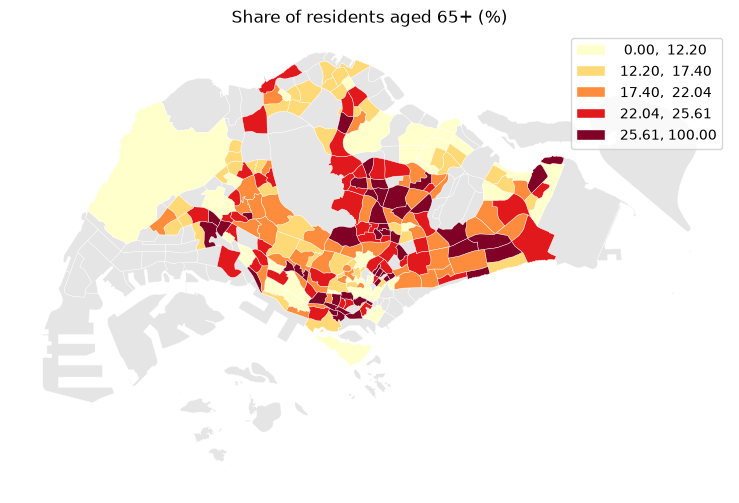

In [25]:
sz["residential"] = sz["pop"] > 0
base = sz[~sz.residential] # all non-residential areas

# plot the chrorpleth
def choropleth(ax, gdf, col, title, cmap="YlOrRd", k=5):
    base.plot(ax=ax, color="#e5e5e5", edgecolor="white", linewidth=0.3) # makes base areas grey colour with white edges
    gdf.plot(ax=ax, column=col, cmap=cmap,
             legend=True, edgecolor="white",
             linewidth=0.3,
             scheme="quantiles",
             k=k)

    ax.set_title(title)
    ax.set_axis_off() # remove any axis markings so we can see the map!

fig, ax = plt.subplots(1, 1, figsize=(16, 6))
choropleth(ax, sz, "pct65", "Share of residents aged 65+ (%)")
plt.savefig("../output/figures/01_elderly_share_and_count.png", dpi=200)
plt.show()

## 3. Acute hospitals location data

Singapore has 20 hospitals. `moh_acute_hospitals.csv` maps their locational data to the name of each hospital.

In [27]:
moh = pd.read_csv("../data/raw/moh_acute_hospitals.csv")
moh

,osm_id,hospital,sector,hospital_type
0,way/75468299,Singapore General Hospital,Public,Acute general
1,relation/2303411,Tan Tock Seng Hospital,Public,Acute general
2,way/34403524,Changi General Hospital,Public,Acute general
3,way/238933465,National University Hospital,Public,Acute general
4,way/746034993,Khoo Teck Puat Hospital,Public,Acute general
5,way/33570275,Sengkang General Hospital,Public,Acute general
6,way/368005263,Ng Teng Fong General Hospital,Public,Acute general
7,way/109104578,Alexandra Hospital,Public,Acute general
8,way/586389089,Woodlands Hospital,Public,Acute general
9,way/41663272,KK Women's and Children's Hospital,Public,Women and children


`oex/oex_sgp_acute_hospitals_osm.geojson` maps each hospital to its locational data as well.

In [28]:
acute = gpd.read_file("../data/raw/oex/oex_sgp_acute_hospitals_osm.geojson").to_crs(SVY21)
acute

,id,name,operator,emergency,postcode,name_zh,name_ms,name_ta,geometry
0,node/6746490215,Farrer Park Hospital,The Farrer Park Company,NaN,217562,花拉公园医院,Hospital Farrer Park,NaN,POINT (30301.645 32766.166)
1,way/34403524,Changi General Hospital,NaN,NaN,NaN,NaN,Hospital Besar Changi,NaN,"POLYGON ((40687.869 35931.713, 40704.619 35911..."
2,way/252835078,Thomson Medical Centre,NaN,NaN,300001,汤申医疗中心,NaN,NaN,"POLYGON ((28885.08 34201.729, 28887.083 34183...."
3,way/41663272,KK Women's and Children's Hospital,NaN,yes,NaN,竹脚妇幼医院,Hospital Wanita dan Kanak-kanak KK,NaN,"POLYGON ((29426.592 32534.086, 29434.772 32515..."
4,way/47134077,Raffles Hospital,NaN,NaN,188770,莱佛士医院,Hospital Raffles,NaN,"POLYGON ((30591.958 31493.95, 30594.496 31491...."
5,way/41890511,Gleneagles Hospital,NaN,yes,NaN,鹰阁医院,Hospital Gleneagles,NaN,"POLYGON ((26411.35 32158.785, 26506.948 32136...."
6,way/397219610,Parkway East Hospital,NaN,NaN,NaN,百汇东岸医院,Hospital Parkway East,NaN,"POLYGON ((36356.731 33061.572, 36379.625 33007..."
7,relation/2303411,Tan Tock Seng Hospital,NaN,yes,308433,陈笃生医院,Hospital Tan Tock Seng,NaN,"MULTIPOLYGON (((29272.26 33718.718, 29274.14 3..."
8,way/751064398,Mount Elizabeth Hospital,NaN,NaN,NaN,伊丽莎白医院,Hospital Mount Elizabeth,NaN,"POLYGON ((28149.143 31870.876, 28161.129 31861..."
9,way/260549167,Mount Elizabeth Novena Hospital,Parkway Health,NaN,NaN,伊丽莎白医诺维娜院,Hospital Mount Elizabeth Novena,NaN,"POLYGON ((29149.729 33812.617, 29154.047 33755..."


In [29]:
# merge the two datasets together like last time
acute = acute[["id", "geometry"]].merge(moh, left_on="id", right_on="osm_id", how="outer", indicator=True)
acute

,id,geometry,osm_id,hospital,sector,hospital_type,_merge
0,node/6746490215,POINT (30301.645 32766.166),node/6746490215,Farrer Park Hospital,Private,Acute,both
1,relation/2303411,"MULTIPOLYGON (((29272.26 33718.718, 29274.14 3...",relation/2303411,Tan Tock Seng Hospital,Public,Acute general,both
2,way/109104578,"POLYGON ((24208.098 29989.769, 24214.062 29926...",way/109104578,Alexandra Hospital,Public,Acute general,both
3,way/1345623876,"POLYGON ((25744.892 34324.829, 25802.74 34319....",way/1345623876,Crawfurd Hospital,Private,Acute,both
4,way/238933465,"POLYGON ((22211.675 30731.716, 22220.555 30696...",way/238933465,National University Hospital,Public,Acute general,both
5,way/252835078,"POLYGON ((28885.08 34201.729, 28887.083 34183....",way/252835078,Thomson Medical Centre,Private,Acute,both
6,way/260549167,"POLYGON ((29149.729 33812.617, 29154.047 33755...",way/260549167,Mount Elizabeth Novena Hospital,Private,Acute,both
7,way/33570275,"POLYGON ((34396.707 41949.391, 34613.16 41904....",way/33570275,Sengkang General Hospital,Public,Acute general,both
8,way/34403524,"POLYGON ((40687.869 35931.713, 40704.619 35911...",way/34403524,Changi General Hospital,Public,Acute general,both
9,way/368005263,"POLYGON ((18154.714 35090.772, 18154.803 35086...",way/368005263,Ng Teng Fong General Hospital,Public,Acute general,both


In [30]:
assert (acute._merge == "both").all(), acute.loc[acute._merge != "both", ["id", "osm_id", "_merge"]]
acute = gpd.GeoDataFrame(acute.drop(columns=["_merge", "id"]).rename(columns={"hospital": "name"}), crs=SVY21)
acute["geometry"] = acute.representative_point()
print(f"oex export: {len(acute)} acute hospitals "
      f"({(acute.sector == 'Public').sum()} public, {(acute.sector == 'Private').sum()} private)")

hospitals = acute[~acute.hospital_type.isin(EXCLUDED_TYPES)].reset_index(drop=True)
print(f"Used as destinations: {len(hospitals)} (excluded types: {sorted(EXCLUDED_TYPES) or 'none'})")
acute.drop(columns="geometry").sort_values(["sector", "name"])

oex export: 20 acute hospitals (11 public, 9 private)


NameError: name 'EXCLUDED_TYPES' is not defined